# 04 Report figures and paper-style tables

Reads the outputs of `01_olivine`, `02_glass` and `03_laicpms` (run those first); only the KL2 example in figure 1 also reads the GLITTER file and `standard_icpms.csv`. Five figures drawn at their printed size (full text width of the report), and `paper_tables.xlsx` with one sheet per dataset.

Colours: the first three slots of a colour-blind-checked categorical palette (blue, orange, aqua), red only for flagged values, grey for individual spots. With more than three groups (the glass samples, the four inclusion suites) identity is also carried by marker shape, so no plot depends on colour alone.

In [1]:
# --- config ---
from pathlib import Path
import sys, re, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter, MaxNLocator
from matplotlib.lines import Line2D
from openpyxl.utils import get_column_letter
warnings.filterwarnings("ignore", message="Unknown extension")
sys.path.insert(0, "src")
from geohelpers import read_glitter, CI_SM89, PM_SM89

DATA, OUT, FIG = Path("data"), Path("outputs"), Path("figures/report")
FIG.mkdir(parents=True, exist_ok=True)
TW = 6.85                                 # report text width (A4, 1.8 cm margins), inches: figures are drawn at printed size
KD, FE2 = (0.27, 0.33), (0.85, 1.00)      # olivine-melt Fe-Mg Kd 0.30 ± 0.03 (Roeder and Emslie 1970); Fe2+/total Fe of the melt
C1, C2, C3, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"     # categorical slots 1-3; red only for flags
INK, MUTED, SPOT, BAND = "#0b0b0b", "#52514e", "#b9b8b2", "#ecebe7"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "standard", "font.size": 8, "axes.titlesize": 8,
                     "axes.labelsize": 8, "legend.fontsize": 6.5, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "axes.edgecolor": MUTED, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.5,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "axes.axisbelow": True})

sheets = lambda f, **kw: pd.read_excel(OUT / f, sheet_name=None, **kw)
first = lambda d: d.set_index(d.columns[0])                          # sheets written with an index: key in column 1
ol, ol4, gl, gl4, la = (sheets(f) for f in ["olivine_final.xlsx", "olivine_step4_standards.xlsx", "glass_final.xlsx",
                                             "glass_step4_standards.xlsx", "laicpms_final.xlsx"])
laqc = sheets("laicpms_standards_QC.xlsx", index_col=0)

OL_OX = ["SiO2", "Al2O3", "Cr2O3", "FeO", "MnO", "MgO", "CaO", "NiO"]
GL_OX = ["SiO2", "TiO2", "Al2O3", "FeO", "MnO", "MgO", "CaO", "Na2O", "K2O", "P2O5", "SO3", "Cl", "F"]
ol_raw, ol_sc = ol4["SC-Olivine raw"].set_index("No."), ol["standards corrected"].set_index("No.")
gl_raw, gl_sc = gl4["VG-2 raw"].set_index("No."), gl["standards corrected"].set_index("No.")
ol_ref, gl_ref = first(ol["references"]).iloc[0], first(gl["references"]).iloc[0]
ol_cf, gl_cf = first(ol4["correction factors"]), first(gl4["correction factors"])
ol_qc, gl_qc = first(ol["standard QC"]), first(gl["standard QC"])
os_, gs = ol["samples corrected"], gl["samples corrected"]
og, gm = ol["grain means"], gl["sample means"].set_index("Sample")
rl, flags, im = first(la["run list"]), first(la["element flags"]), la["inclusion means"]
FLAGGED = flags.index[flags.flag.notna()].tolist()
SYM = lambda c: re.sub(r"\d", "", c)
CHEM = lambda s: s.translate(str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉"))   # oxide formula with subscripts: Al2O3 -> Al₂O₃

def plain_log(ax, xticks=None, yticks=None):                       # log axes labelled 0.1, 1, 10 instead of 10^-1, 10^0, 10^1
    for axis, ticks in [(ax.xaxis, xticks), (ax.yaxis, yticks)]:
        if axis.get_scale() == "log":
            if ticks is not None: axis.set_ticks(ticks)
            axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); axis.set_minor_formatter(NullFormatter())

def panel(ax, letter):
    ax.text(-0.01, 1.03, f"({letter})", transform=ax.transAxes, fontweight="bold", ha="right", va="bottom")

## Figure 1. Methodology examples

(a, b) A standard plotted against analysis number in each EPMA session, with the value removed by eye in step 3. (c) KL2 boron, the element with the strongest trend: CF of the train analyses (fitted) and of the test analyses (not fitted) against time, with the fitted line used for the correction. (d) Analytical totals after correction, with the 98 to 102 wt% window of step 9.

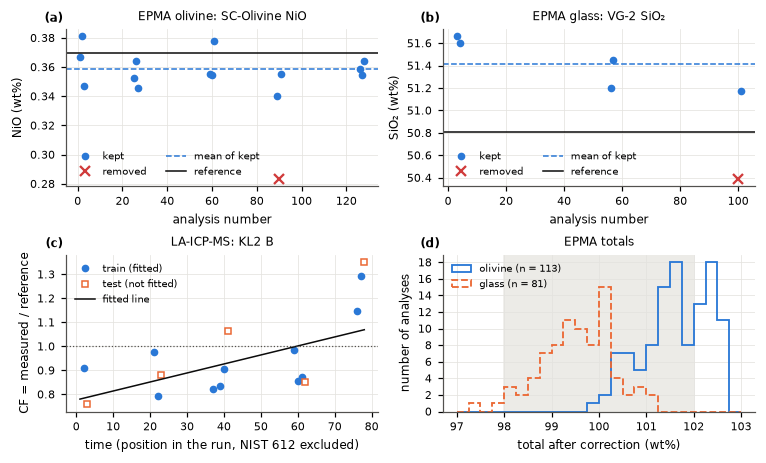

olivine totals > 102: 42 | glass totals < 98: 2 > 102: 0


In [2]:
filt = read_glitter(DATA / "170919s_9_global_tephra 1_Froukje2.csv", "Trace Element Concentrations MDL filtered")
truth = pd.read_csv(DATA / "standard_icpms.csv", index_col=0).loc["KL2-G"]
fit = laqc["KL2 fit"]

def std_panel(ax, raw, sc, ref, el, title):
    keep = sc[el].reindex(raw.index).notna()
    ax.plot(raw.index[keep], raw.loc[keep, el], "o", ms=4, color=C1, label="kept")
    ax.plot(raw.index[~keep], raw.loc[~keep, el], "x", ms=6, mew=1.5, color=RED, label="removed")
    ax.axhline(raw.loc[keep, el].mean(), ls="--", lw=1, color=C1, label="mean of kept")
    ax.axhline(ref[el], color=INK, lw=1, label="reference")
    ax.set(xlabel="analysis number", ylabel=f"{CHEM(el)} (wt%)", title=title)
    ax.legend(loc="lower left", ncol=2)

fig, axs = plt.subplots(2, 2, figsize=(TW, 4.10), layout="constrained")
std_panel(axs[0, 0], ol_raw, ol_sc, ol_ref, "NiO", "EPMA olivine: SC-Olivine NiO")
std_panel(axs[0, 1], gl_raw, gl_sc, gl_ref, "SiO2", "EPMA glass: VG-2 SiO₂")
ax = axs[1, 0]
for split, mk, col in [("train", "o", C1), ("test", "s", C2)]:
    k = rl[rl.material.eq("KL2") & rl.split.eq(split)]
    ax.plot(k.time, filt.loc[k.index, "B11"] / truth["B"], mk, ms=4, color=col, mfc=col if split == "train" else "white",
            label=f"{split} ({'fitted' if split == 'train' else 'not fitted'})")
t = np.array([rl.time.min(), rl.time.max()])
ax.plot(t, fit.at["B11", "slope"] * t + fit.at["B11", "intercept"], color=INK, lw=1, label="fitted line")
ax.axhline(1, color=MUTED, lw=0.8, ls=":")
ax.set(xlabel="time (position in the run, NIST 612 excluded)", ylabel="CF = measured / reference", title="LA-ICP-MS: KL2 B")
ax.legend(loc="upper left")
ax = axs[1, 1]
ax.axvspan(98, 102, color=BAND, zorder=0)
for d, name, col, ls in [(os_, "olivine", C1, "-"), (gs, "glass", C2, "--")]:
    ax.hist(d.Total, bins=np.arange(97, 103.01, 0.25), histtype="step", color=col, ls=ls, lw=1.2, label=f"{name} (n = {len(d)})")
ax.set(xlabel="total after correction (wt%)", ylabel="number of analyses", title="EPMA totals")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(loc="upper left")
for a, l in zip(axs.flat, "abcd"): panel(a, l)
fig.savefig(FIG / "fig1_methodology_examples.png"); plt.show()
print("olivine totals > 102:", int((os_.Total > 102).sum()), "| glass totals < 98:", int((gs.Total < 98).sum()), "> 102:", int((gs.Total > 102).sum()))

## Figure 2. Data quality

(a, b) EPMA correction factors per oxide (step 5): grey band ±5 %, red bars outside it with their value. (c) EPMA precision (2RSD of the corrected standard) against accuracy (hold-out test, step 6) for every oxide; above the dashed line the deviation would be larger than the scatter. Labelled: oxides with |accuracy| of 5 % or more. (d) LA-ICP-MS reportability (step 6): precision from KL2 (train and test), accuracy from BCR-2G; red = flagged (dashed lines at 20 % and 15 %); labelled: flagged elements and those with accuracy worse than 5 % or RSTD above 15 %. Ca43 (internal standard) and As (no BCR-2G reference) are not plotted.

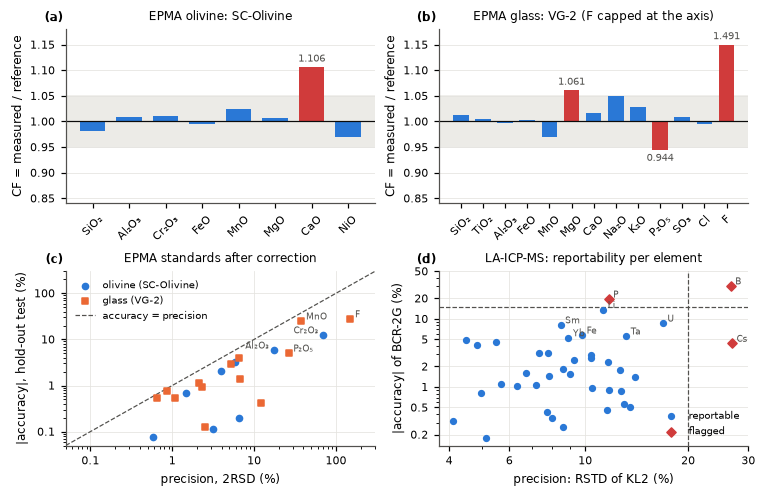

EPMA |accuracy| range: 0.076 to 27.9 %


In [3]:
def cf_panel(ax, cf, title, lo=0.85, hi=1.15):
    v = cf.CF
    flag = (v - 1).abs() > 0.05
    ax.axhspan(0.95, 1.05, color=BAND, zorder=0)
    ax.bar(range(len(v)), v.clip(lo, hi) - 1, bottom=1, width=0.7, color=np.where(flag, RED, C1))
    for i, (el, x) in enumerate(v.items()):
        if flag[el]:
            y = min(max(x, lo), hi)
            ax.annotate(f"{x:.3f}", (i, y), xytext=(0, 2 if x > 1 else -2), textcoords="offset points",
                        ha="center", va="bottom" if x > 1 else "top", fontsize=6.5, color=MUTED)
    ax.axhline(1, color=INK, lw=0.8)
    ax.set_xticks(range(len(v)), [CHEM(o) for o in v.index], rotation=45)
    ax.set(ylim=(lo - 0.01, hi + 0.03), ylabel="CF = measured / reference", title=title)
    ax.grid(axis="x", visible=False)

fig, axs = plt.subplots(2, 2, figsize=(TW, 4.41), layout="constrained")
cf_panel(axs[0, 0], ol_cf, "EPMA olivine: SC-Olivine")
cf_panel(axs[0, 1], gl_cf, "EPMA glass: VG-2 (F capped at the axis)")
ax = axs[1, 0]
for qc, name, mk, col, dx in [(ol_qc, "olivine (SC-Olivine)", "o", C1, -3), (gl_qc, "glass (VG-2)", "s", C2, 3)]:
    x, y = qc.precision_2RSD_pct, qc.accuracy_pct.abs()
    ax.scatter(x, y, marker=mk, s=16, color=col, label=name, zorder=3)
    for el in qc.index[y >= 5]:                                    # label only the oxides with |accuracy| of 5 % or more
        ax.annotate(CHEM(el), (x[el], y[el]), xytext=(dx, 1), textcoords="offset points", ha="right" if dx < 0 else "left",
                    fontsize=6, color=MUTED)
lim = [0.05, 300]
ax.plot(lim, lim, ls="--", lw=0.8, color=MUTED, label="accuracy = precision")
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="precision, 2RSD (%)", ylabel="|accuracy|, hold-out test (%)",
       title="EPMA standards after correction")
ax.legend(loc="upper left"); plain_log(ax)
ax = axs[1, 1]
r = flags.drop(index="Ca43").dropna(subset=["BCR2G_accuracy_pct"])
x, y, f = r.KL2_RSTD_pct, r.BCR2G_accuracy_pct.abs(), r.flag.notna()
ax.scatter(x[~f], y[~f], s=14, color=C1, label="reportable", zorder=3)
ax.scatter(x[f], y[f], s=18, marker="D", color=RED, label="flagged", zorder=3)
for el in r.index[f | (y >= 5) | (x >= 15)]:                         # flagged, accuracy worse than 5 % or RSTD above 15 %
    ax.annotate(SYM(el), (x[el], y[el]), xytext=(3, 1), textcoords="offset points", fontsize=6, color=MUTED)
ax.axvline(20, ls="--", lw=0.8, color=MUTED); ax.axhline(15, ls="--", lw=0.8, color=MUTED)
ax.set(xscale="log", yscale="log", xlabel="precision: RSTD of KL2 (%)", ylabel="|accuracy| of BCR-2G (%)",
       title="LA-ICP-MS: reportability per element")
ax.legend(loc="lower right"); plain_log(ax, xticks=[4, 6, 10, 20, 30], yticks=[0.2, 0.5, 1, 2, 5, 10, 20, 50])
for a, l in zip(axs.flat, "abcd"): panel(a, l)
fig.savefig(FIG / "fig2_data_quality.png"); plt.show()
print("EPMA |accuracy| range:", round(min(ol_qc.accuracy_pct.abs().min(), gl_qc.accuracy_pct.abs().min()), 3), "to",
      round(max(ol_qc.accuracy_pct.abs().max(), gl_qc.accuracy_pct.abs().max()), 1), "%")

## Figure 3. Basaltic glasses: Harker diagrams

Individual spots (grey) and sample means ± 2SD against MgO. Analyses excluded in step 9 (No. 49 and 65) are not shown.

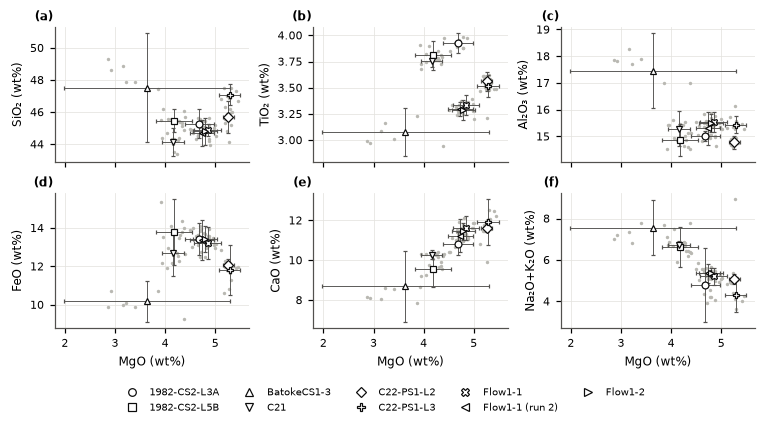

In [4]:
G = gs[~gs.exclude].copy()
G["Na2O+K2O"] = G.Na2O + G.K2O
YS = ["SiO2", "TiO2", "Al2O3", "FeO", "CaO", "Na2O+K2O"]
gg = G.groupby("Sample")
mean, sd2 = gg[["MgO"] + YS].mean(), 2 * gg[["MgO"] + YS].std()
MARK = dict(zip(mean.index, ["o", "s", "^", "v", "D", "P", "X", "<", ">"]))

fig, axs = plt.subplots(2, 3, figsize=(TW, 3.73), sharex=True, layout="constrained")
for ax, y, l in zip(axs.flat, YS, "abcdef"):
    ax.scatter(G.MgO, G[y], s=5, color=SPOT, lw=0, zorder=1)
    for s in mean.index:
        ax.errorbar(mean.at[s, "MgO"], mean.at[s, y], xerr=sd2.at[s, "MgO"], yerr=sd2.at[s, y], fmt=MARK[s], ms=4.5,
                    mfc="white", mec=INK, mew=0.8, ecolor=MUTED, elinewidth=0.6, capsize=1.5, zorder=3, label=s.replace("UnknA-", ""))
    ax.set_ylabel(f"{CHEM(y)} (wt%)")
    panel(ax, l)
for ax in axs[1]: ax.set_xlabel("MgO (wt%)")
h = [Line2D([], [], ls="none", marker=MARK[s], ms=5, mfc="white", mec=INK, mew=0.8, label=s.replace("UnknA-", "")) for s in mean.index]
fig.legend(handles=h, loc="outside lower center", ncol=5)
fig.savefig(FIG / "fig3_glass_harker.png"); plt.show()

## Figure 4. Olivines: minor elements against forsterite

Grain means ± 2SD. Panel (a) also gives the Fo of olivine in Fe-Mg equilibrium with the mean C21 glass (Kd = 0.30 ± 0.03, 85 to 100 % of the iron as Fe²⁺; FeO in the glass is total iron), which lies below the axis range. This assumes the C21 glass and the C21MI olivines belong to the same sample.

Fo in equilibrium with glass C21: 63.9 to 71.8; C21MI grains: Fo 78.6 to 85.6


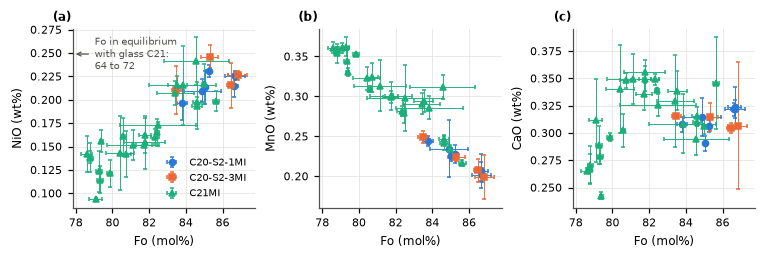

In [5]:
c21 = gm.loc["UnknA-C21"]
ratio = (c21.FeO / 71.844) / (c21.MgO / 40.304)                     # molar FeO/MgO of the glass, all Fe as FeO
lo, hi = 100 / (1 + KD[1] * FE2[1] * ratio), 100 / (1 + KD[0] * FE2[0] * ratio)
c21ol = og.loc[og.Sample.eq("UnkA-C21MI"), "Fo"]
print(f"Fo in equilibrium with glass C21: {lo:.1f} to {hi:.1f}; C21MI grains: Fo {c21ol.min():.1f} to {c21ol.max():.1f}")

SAMP = sorted(og.Sample.unique())
STY = dict(zip(SAMP, [(C1, "o"), (C2, "s"), (C3, "^")]))
fig, axs = plt.subplots(1, 3, figsize=(TW, 2.24), sharex=True, layout="constrained")
for ax, y, l in zip(axs, ["NiO", "MnO", "CaO"], "abc"):
    for s, d in og.groupby("Sample"):
        col, mk = STY[s]
        ax.errorbar(d.Fo, d[y], xerr=d.Fo_2SD, yerr=d[f"{y}_2SD"], fmt=mk, ms=4, color=col, ecolor=col,
                    elinewidth=0.6, capsize=1.5, label=s.replace("UnkA-", ""))
    ax.set(xlabel="Fo (mol%)", ylabel=f"{y} (wt%)")
    panel(ax, l)
axs[0].legend(loc="lower right")
axs[0].annotate(f"Fo in equilibrium\nwith glass C21:\n{lo:.0f} to {hi:.0f}", xy=(0, 0.86), xycoords="axes fraction",
                xytext=(0.12, 0.86), textcoords="axes fraction", va="center", fontsize=6.5, color=MUTED,
                arrowprops=dict(arrowstyle="->", color=MUTED, lw=0.8))
fig.savefig(FIG / "fig4_olivine.png"); plt.show()

## Figure 5. Melt inclusions: normalised trace-element patterns

Median of each suite (line) and its range (shaded); repeat analyses of one inclusion are averaged first. (a) REE normalised to CI chondrite, (b) multi-element pattern normalised to primitive mantle, both Sun and McDonough (1989). Flagged elements (step 6) and the Pb of the inclusions with probable Pb contamination (step 7) are left out. MC99U (two inclusions) is in grey.

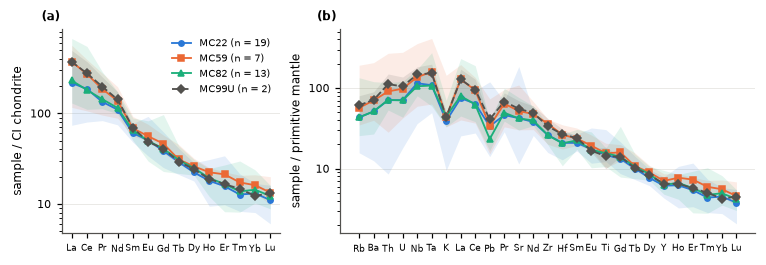

left out of (b): ['Cs', 'P'] | Pb removed for 8 inclusions


In [6]:
REE = ["La139", "Ce140", "Pr141", "Nd146", "Sm147", "Eu151", "Gd157", "Tb159", "Dy163", "Ho165", "Er166", "Tm169", "Yb172", "Lu175"]
SPIDER = ["Cs133", "Rb85", "Ba138", "Th232", "U238", "Nb93", "Ta181", "K39", "La139", "Ce140", "Pb208", "Pr141", "Sr88", "P31",
          "Nd146", "Zr90", "Hf178", "Sm147", "Eu151", "Ti47", "Gd157", "Tb159", "Dy163", "Y89", "Ho165", "Er166", "Tm169", "Yb172", "Lu175"]
spider = [c for c in SPIDER if c not in FLAGGED]
plot = im.copy()
plot.loc[plot.Pb_contaminated.astype(bool), "Pb208"] = np.nan
GSTY = {"MC22": (C1, "o", "-"), "MC59": (C2, "s", "-"), "MC82": (C3, "^", "-"), "MC99U": (MUTED, "D", "--")}

fig, axs = plt.subplots(1, 2, figsize=(TW, 2.30), gridspec_kw={"width_ratios": [1, 1.9]}, layout="constrained")
for ax, cols, ref, ylab, l in [(axs[0], REE, CI_SM89, "sample / CI chondrite", "a"),
                               (axs[1], spider, PM_SM89, "sample / primitive mantle", "b")]:
    x = np.arange(len(cols))
    norm = pd.Series({c: ref[SYM(c)] for c in cols})
    for g, (col, mk, ls) in GSTY.items():
        d = plot[plot.group.eq(g)]
        v = d[cols] / norm
        ax.fill_between(x, v.min(), v.max(), color=col, alpha=0.12, lw=0)
        ax.plot(x, v.median(), ls=ls, marker=mk, ms=3.5, lw=1.2, color=col, label=f"{g} (n = {len(d)})")
    ax.set_xticks(x, [SYM(c) for c in cols]); ax.tick_params(axis="x", labelsize=6)
    ax.set(yscale="log", ylabel=ylab)
    ax.grid(axis="x", visible=False); plain_log(ax)
    panel(ax, l)
axs[0].legend(loc="upper right")
fig.savefig(FIG / "fig5_melt_inclusions.png"); plt.show()
print("left out of (b):", [SYM(c) for c in SPIDER if c in FLAGGED], "| Pb removed for", int(plot.Pb_contaminated.sum()), "inclusions")

## Check: host olivine in the inclusion analyses

The major elements measured by LA-ICP-MS are converted to oxides (Fe as FeO) and summed; a melt inclusion should sum to roughly 100 wt%. If the laser also ablates the host olivine, its Mg, Si, Fe and Mn enter the signal without Ca, the internal standard, so the sum rises and follows those elements, while elements that olivine does not contain are unaffected. Elements that correlate with the sum (r > 0.5) are marked h in the inclusion table and not interpreted.

In [7]:
la_an = la["analyses corrected"]
OXF = {"Na23": 1.3480, "Mg24": 1.6583, "Al27": 1.8895, "Si29": 2.1393, "P31": 2.2914, "K39": 1.2046,
       "Ca43": 1.3992, "Ti47": 1.6681, "Mn55": 1.2912, "Fe57": 1.2865}          # element to oxide, Fe as FeO
osum = sum(la_an[c] * f for c, f in OXF.items()) / 1e4                         # ug/g to wt%
EL41 = [c for c in la_an.columns if re.fullmatch(r"[A-Z][a-z]?\d+", c)]
r_sum = pd.Series({c: np.corrcoef(osum, la_an[c])[0, 1] for c in EL41}).sort_values(ascending=False)
HOST = r_sum.index[r_sum > 0.5].tolist()
print(f"oxide sums: {osum.min():.0f} to {osum.max():.0f} wt%; {osum.between(95, 105).sum()} of {len(osum)} within 95 to 105 wt%")
print("r with the oxide sum:", r_sum.head(7).round(2).to_dict(), "| all others: |r| <=", round(r_sum.iloc[7:].abs().max(), 2))

oxide sums: 67 to 416 wt%; 13 of 47 within 95 to 105 wt%
r with the oxide sum: {'Si29': 0.99, 'Mg24': 0.98, 'Fe57': 0.98, 'Mn55': 0.96, 'Sc45': 0.69, 'Li7': 0.39, 'Yb172': 0.15} | all others: |r| <= 0.27


## Paper-style tables

One sheet per dataset. Samples: n and mean ± 2SD, rounded to the precision of the 2SD. EPMA standards: the uncorrected mean of the analyses kept in step 3 next to the reference value, with the correction factor, precision and hold-out accuracy, so the correction can be followed (the corrected standard equals its reference by construction and is not shown). LA-ICP-MS standards: BCR-2G and the KL2 test split, neither used for the correction. Footnotes are generated from the outputs of 01 to 03.

In [8]:
def pm(m, s=np.nan):
    if pd.isna(m): return ""
    if pd.isna(s) or s == 0:
        return f"{m:.3g}" if abs(m) < 1000 else f"{m:.0f}"
    d = int(np.clip(1 - np.floor(np.log10(abs(s))), 0, 4))
    return f"{m:.{d}f} ± {s:.{d}f}"

def means_table(means, cols, index):
    return pd.DataFrame({"n": means["n"].astype(int).values,
                         **{c: [pm(m, s) for m, s in zip(means[c], means[f"{c}_2SD"])] for c in cols}}, index=index)

def std_block(name, raw, sc, ref, cf, qc, cols):
    keep = raw[cols].where(sc[cols].reindex(raw.index).notna())      # the values that gave the CF (step 3 removals excluded)
    n = keep.count()
    rows = {f"{name} measured, uncorrected": {"n": int(n.max()), **{c: pm(keep[c].mean(), 2 * keep[c].std()) for c in cols}},
            f"{name} reference": {"n": "", **{c: f"{ref[c]:.4g}" for c in cols}},
            "Correction factor (measured / reference)": {"n": "", **{c: f"{cf.at[c, 'CF']:.3f}" for c in cols}},
            "Precision, 2RSD (%)": {"n": "", **{c: f"{qc.at[c, 'precision_2RSD_pct']:.1f}" for c in cols}},
            "Accuracy, hold-out test (%)": {"n": "", **{c: f"{qc.at[c, 'accuracy_pct']:+.1f}" for c in cols}}}
    short = n[n < n.max()]
    note = f"{name}: n = {int(n.max())}" + ("" if short.empty else ", except " + ", ".join(f"{c} (n = {int(k)})" for c, k in short.items())) \
           + " after the outliers removed in step 3. The corrected standard equals its reference by construction."
    return pd.DataFrame(rows).T, note

def epma_notes(samples, qc, dl, name):
    notes = []
    excl = samples.loc[samples.exclude.astype(bool), "No."].astype(int).tolist()
    note = samples.get("note", pd.Series("", index=samples.index)).fillna("")   # only the glass has single-oxide exclusions
    part = pd.DataFrame({"No.": samples["No."], "note": note})[note.str.contains(" excluded:")]
    if excl or len(part):
        notes.append("Excluded from the means: " + "; ".join(([f"analyses No. {', '.join(map(str, excl))}"] if excl else [])
                     + [f"{t.split(' excluded')[0]} of No. {int(no)}" for no, t in part.values]) + ".")
    f = qc[qc.CF_flag.astype(bool)]
    if len(f):
        notes.append("Correction factor outside ±5 % (step 5): " + ", ".join(f"{o} ({v:.3f})" for o, v in f.CF.items()) + ".")
    b = dl[dl.n_below_DL > 0].sort_values("n_below_DL", ascending=False)
    if len(b):
        notes.append("Below the detection limit (flagged, kept in the means): "
                     + ", ".join(f"{o} in {int(k)}" for o, k in b.n_below_DL.items()) + f" of {int(dl.n.iloc[0])} analyses.")
    return notes

# glass
GCOLS = GL_OX + ["Total"]
blk, std_note = std_block("VG-2", gl_raw, gl_sc, gl_ref, gl_cf, gl_qc, GL_OX)
t_gl = pd.concat([means_table(gm, GCOLS, gm.index.str.replace("UnknA-", "")), blk])[["n"] + GCOLS]
gdl = first(gl["detection limits"])
notes_gl = (["Mean ± 2SD in wt%; n = number of spots. All oxides corrected with VG-2: corrected = raw / CF, CF = VG-2 measured / reference."]
            + epma_notes(gs, gl_qc, gdl, "glass")
            + [f"F is not quantitative: the VG-2 reference value ({gl_ref['F']:.3f} wt%) is below the median detection limit "
               f"({gdl.at['F', 'DL_median']:.3f} wt%), so its correction factor is unreliable.",
               "Flow1-1 (run 2): the same sample measured twice under one name; both runs agree within 2SD.", std_note])

# olivine
OCOLS = OL_OX + ["Total", "Fo"]
blk, std_note = std_block("SC-Olivine", ol_raw, ol_sc, ol_ref, ol_cf, ol_qc, OL_OX)
t_ol = pd.concat([means_table(og, OCOLS, og.Grain.str.replace("UnkA-", "")), blk])[["n"] + OCOLS]
notes_ol = (["Mean ± 2SD in wt%, Fo in mol%; n = number of spots per grain. Corrected with SC-Olivine: corrected = raw / CF, CF = SC-Olivine measured / reference."]
            + epma_notes(os_, ol_qc, first(ol["detection limits"]), "olivine") + [std_note])

# melt inclusions
LEL = [c for c in im.columns if c not in ("group", "inclusion", "n", "Pb_contaminated")]
t_la = pd.DataFrame({"n": im.n.astype(int).values, **{c: [pm(v) for v in im[c]] for c in LEL}}, index=im.inclusion.values)
pbc = im.Pb_contaminated.astype(bool).values
t_la.loc[pbc, "Pb208"] = t_la.loc[pbc, "Pb208"] + " c"

def la_rows(name, key):
    q = laqc[key]
    return {f"{name} measured": {"n": int(q.n.max()), **{c: pm(q.at[c, "average"], np.nan if c == "Ca43" else q.at[c, "2STDev"]) for c in LEL}},
            f"{name} reference": {"n": "", **{c: pm(q.at[c, "reference"], q.at[c, "reference_unc_95"]) for c in LEL}},
            f"{name} accuracy (%)": {"n": "", **{c: "" if c == "Ca43" or pd.isna(q.at[c, "accuracy_pct"]) else f"{q.at[c, 'accuracy_pct']:+.1f}" for c in LEL}}}

rows = {**la_rows("BCR-2G", "BCR-2G"), **la_rows("KL2 test split", "KL2 test"),
        "KL2 precision, RSTD (%)": {"n": "", **{c: "" if c == "Ca43" else f"{laqc['KL2 all'].at[c, 'RSTD_pct']:.1f}" for c in LEL}}}
t_la = pd.concat([t_la, pd.DataFrame(rows).T])[["n"] + LEL]
t_la.columns = ["n"] + [f"{c}{' (IS)' if c == 'Ca43' else ''}{' *' if c in FLAGGED else ''}{' h' if c in HOST else ''}" for c in LEL]
test_runs = ", ".join(rl.loc[rl.split.eq("test"), "run"].astype(int).astype(str))
notes_la = ["Concentrations in µg/g; repeat analyses of one inclusion averaged (n). Drift corrected with a linear fit of CF = measured / reference "
            "of the KL2 train analyses against time: corrected = raw / CF(time); all elements except Ca43.",
            "* flagged element (step 6): RSTD of KL2 above 20 % or BCR-2G accuracy worse than ±15 %.",
            "c: Pb/Pb* above 5, probable Pb contamination; reported but not interpreted.",
            f"h: in the inclusions, partly host olivine ablated with the inclusion: the major-element oxide sums range from {osum.min():.0f} "
            f"to {osum.max():.0f} wt% and correlate with these elements (r = {r_sum[HOST].min():.2f} to {r_sum[HOST].max():.2f}); not interpreted.",
            "Ca43 (IS): internal standard, fixed in GLITTER to a value entered for each analysis; not measured or corrected.",
            f"BCR-2G: run 70 excluded (normalised to the wrong Ca in GLITTER). KL2 test split: runs {test_runs}, not used for the correction. "
            "KL2 precision: train and test analyses together.",
            "Reference values: GeoReM (Standards.xlsx) ± 95 % uncertainty; CI chondrite and primitive mantle: Sun and McDonough (1989)."]

with pd.ExcelWriter(OUT / "paper_tables.xlsx", engine="openpyxl") as xw:
    for sheet, t, notes in [("Glass (EPMA)", t_gl, notes_gl), ("Olivine (EPMA)", t_ol, notes_ol), ("Melt inclusions (LA-ICP-MS)", t_la, notes_la)]:
        t.to_excel(xw, sheet_name=sheet)
        ws = xw.sheets[sheet]
        for k, note in enumerate(notes):
            ws.cell(row=len(t) + 3 + k, column=1, value=note)
        ws.column_dimensions["A"].width = 38
        for j in range(2, t.shape[1] + 2):
            ws.column_dimensions[get_column_letter(j)].width = 6 if j == 2 else 14
        ws.freeze_panes = "B2"
for name, t, notes in [("glass", t_gl, notes_gl), ("olivine", t_ol, notes_ol), ("melt inclusions", t_la, notes_la)]:
    print(f"{name}: {t.shape[0]} rows x {t.shape[1]} columns"); print("  " + "\n  ".join(notes))
t_gl.tail(6)

glass: 14 rows x 15 columns
  Mean ± 2SD in wt%; n = number of spots. All oxides corrected with VG-2: corrected = raw / CF, CF = VG-2 measured / reference.
  Excluded from the means: analyses No. 49, 65; SO3 of No. 32; Cl of No. 70.
  Correction factor outside ±5 % (step 5): MgO (1.061), P2O5 (0.944), F (1.491).
  Below the detection limit (flagged, kept in the means): SO3 in 18, F in 12, K2O in 1, P2O5 in 1, Cl in 1 of 81 analyses.
  F is not quantitative: the VG-2 reference value (0.032 wt%) is below the median detection limit (0.037 wt%), so its correction factor is unreliable.
  Flow1-1 (run 2): the same sample measured twice under one name; both runs agree within 2SD.
  VG-2: n = 6, except SiO2 (n = 5), Al2O3 (n = 5), Cl (n = 5) after the outliers removed in step 3. The corrected standard equals its reference by construction.
olivine: 42 rows x 11 columns
  Mean ± 2SD in wt%, Fo in mol%; n = number of spots per grain. Corrected with SC-Olivine: corrected = raw / CF, CF = SC-Olivin

,n,SiO2,TiO2,Al2O3,FeO,MnO,MgO,CaO,Na2O,K2O,P2O5,SO3,Cl,F,Total
Flow1-2,9,44.81 ± 0.83,3.286 ± 0.095,15.50 ± 0.33,13.43 ± 0.70,0.245 ± 0.056,4.79 ± 0.23,11.44 ± 0.43,3.63 ± 0.24,1.75 ± 0.12,0.771 ± 0.079,0.040 ± 0.015,0.147 ± 0.079,0.059 ± 0.077,99.9 ± 1.1
"VG-2 measured, uncorrected",6,51.42 ± 0.45,1.858 ± 0.043,14.016 ± 0.090,11.88 ± 0.30,0.213 ± 0.081,7.12 ± 0.15,11.30 ± 0.12,2.75 ± 0.19,0.195 ± 0.013,0.189 ± 0.050,0.360 ± 0.019,0.0327 ± 0.0039,0.048 ± 0.072,NaN
VG-2 reference,,50.81,1.85,14.06,11.84,0.22,6.71,11.12,2.62,0.19,0.2,0.3571,0.03291,0.032,NaN
Correction factor (measured / reference),,1.012,1.005,0.997,1.003,0.970,1.061,1.016,1.050,1.028,0.944,1.009,0.994,1.491,NaN
"Precision, 2RSD (%)",,0.9,2.3,0.6,2.5,37.8,2.1,1.1,6.8,6.5,26.5,5.2,12.0,150.2,NaN
"Accuracy, hold-out test (%)",,-0.7,+0.9,-0.5,+0.1,-25.0,-1.2,-0.5,+1.4,+3.9,-5.1,-2.9,+0.4,+27.9,NaN
